# 01 Tag disaster reports
Load time-ordered reports, classify local embeddings, match places, and inspect masked tags.

In [1]:
# Bootstrap: make the repo importable whether the notebook runs in IBM's container or ours
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from surgedesk.envcheck import run
ENV = run()

SurgeDesk environment check
arch            : arm64  (byte order: little)
python          : 3.13.0
cores / RAM     : 8 / None GB
disk free       : 29.0 GB
NNPA flag       : None
zDNN libs       : none found
ROOT            : /Users/saikarthikbattula/Documents/ChatGPT/Person1/surgedesk
threads setting : 2   demo event: hurricane_harvey_2017
----------------------------------------------------------------
  numpy              2.1.2
  pandas             2.2.3
  scikit-learn       1.7.0
  xgboost            NOT INSTALLED
  torch              2.9.0
  transformers       4.46.2
  tokenizers         0.20.3
  huggingface_hub    0.33.1
  llama_cpp_python   NOT INSTALLED
  ipywidgets         8.1.7
  matplotlib         3.10.3
  joblib             1.5.1
  torch_nnpa         NOT INSTALLED
  nbconvert          7.17.2
----------------------------------------------------------------
  --  humaid_dir     /Users/saikarthikbattula/Documents/ChatGPT/Person1/surgedesk/data/raw/humaid
  --  gazetteer_dir  /U

## Input mode
Without the real data pack and local MiniLM, this notebook runs an explicitly synthetic fixture walkthrough. Fixture embeddings are precomputed test inputs; they do not verify MiniLM or establish real-data performance. Once the pack and MiniLM exist, Restart Kernel and Run All automatically uses the real workflow.

Synthetic walkthrough files stay under `outputs/_stub/`; the real event registry and outputs remain unchanged.

In [2]:
import json
import tempfile
from unittest.mock import patch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from surgedesk import config, data_humaid, embed, tag
from surgedesk.contracts import Report, Tagged
from surgedesk.fileio import read_json, read_jsonl, write_jsonl, load_embeddings, save_embeddings
from surgedesk.geo import Gazetteer, PlaceMatcher
from surgedesk.textutil import mask_privacy

FIXTURE_MODE = not (config.HUMAID_DIR.is_dir() and (config.MINILM_DIR / 'config.json').is_file())
outputs_root = config.STUB_OUTPUTS if FIXTURE_MODE else config.OUTPUTS
fixture_model_dir = tempfile.TemporaryDirectory(prefix='surgedesk-notebook-') if FIXTURE_MODE else None
classifier_path = pathlib.Path(fixture_model_dir.name) / config.CLASSIFIER_PATH.name if FIXTURE_MODE else config.CLASSIFIER_PATH
event = config.FIXTURE_EVENT if FIXTURE_MODE else config.DEMO_EVENT
display(Markdown('**Synthetic fixture walkthrough. Real-data verification pending.**' if FIXTURE_MODE else '**Real-data workflow; held-out demo event excluded from training.**'))

**Synthetic fixture walkthrough. Real-data verification pending.**

In [3]:
if FIXTURE_MODE:
    with patch.object(config, 'OUTPUTS', outputs_root):
        summary = data_humaid.build_reports(humaid_dir=config.FIXTURES / 'humaid', source='synthetic')
else:
    summary = data_humaid.build_reports()
display(summary)

              event  n_reports                first                 last states                                                                                                                                                                                                                                                                                                                                                  label_counts
      fixture_event         20 2017-08-27T10:00:00Z 2017-08-27T12:50:00Z ["TX"]                                                                                           {"caution_and_advice": 1, "displaced_people_and_evacuations": 1, "infrastructure_and_utility_damage": 4, "injured_or_dead_people": 1, "not_humanitarian": 1, "requests_or_urgent_needs": 8, "rescue_volunteering_or_donation_effort": 2, "sympathy_and_support": 2}
fixture_train_event         46 2017-08-28T08:00:00Z 2017-08-28T20:48:00Z ["TX"] {"caution_and_advice": 4, "displaced_people_and_evacuations"

,event,n_reports,first,last,states,label_counts
0,fixture_event,20,2017-08-27T10:00:00Z,2017-08-27T12:50:00Z,"[""TX""]","{""caution_and_advice"": 1, ""displaced_people_an..."
1,fixture_train_event,46,2017-08-28T08:00:00Z,2017-08-28T20:48:00Z,"[""TX""]","{""caution_and_advice"": 4, ""displaced_people_an..."


In [4]:
events = read_json(outputs_root / 'events.json')
for e in events:
    if FIXTURE_MODE:
        vectors = load_embeddings(config.FIXTURES / 'outputs' / e / config.EMBEDDINGS_FILE)
        save_embeddings(config.event_file(e, config.EMBEDDINGS_FILE, stub=FIXTURE_MODE), vectors)
        print(e, vectors.shape, 'precomputed synthetic fixture vectors; not a MiniLM benchmark')
    else:
        embed.embed_event(e)

if FIXTURE_MODE and (config.MINILM_DIR / 'config.json').is_file():
    import numpy as np
    samples = read_jsonl(config.event_file(event, config.REPORTS_FILE, stub=FIXTURE_MODE), Report)[:3]
    actual_vectors = embed.Embedder().encode([r.text for r in samples])
    assert actual_vectors.shape == (len(samples), config.EMBED_DIM)
    assert np.allclose(np.linalg.norm(actual_vectors, axis=1), 1.0, atol=1e-5)
    display(pd.DataFrame({'report_id': [r.report_id for r in samples],
                          'MiniLM_vector_norm': np.linalg.norm(actual_vectors, axis=1)}))
    print('Actual local MiniLM encoding passed; fixture pipeline below uses the precomputed fixture vectors.')

fixture_event (20, 384) precomputed synthetic fixture vectors; not a MiniLM benchmark
fixture_train_event (46, 384) precomputed synthetic fixture vectors; not a MiniLM benchmark


In [5]:
training_events = [config.FIXTURE_TRAIN_EVENT] if FIXTURE_MODE else config.train_events(events)
metrics = tag.train_classifier(training_events, allow_fixture=FIXTURE_MODE, classifier_path=classifier_path, outputs_root=outputs_root)
display(metrics)

{'classes': ['caution_and_advice',
  'displaced_people_and_evacuations',
  'dont_know_cant_judge',
  'infrastructure_and_utility_damage',
  'injured_or_dead_people',
  'missing_or_found_people',
  'not_humanitarian',
  'other_relevant_information',
  'requests_or_urgent_needs',
  'rescue_volunteering_or_donation_effort',
  'sympathy_and_support'],
 'train_events': ['fixture_train_event'],
 'trained_at': '2026-10-17T20:03:45Z',
 'dev_macro_f1': None}

In [6]:
for e in events:
    if FIXTURE_MODE:
        reports = read_jsonl(config.event_file(e, config.REPORTS_FILE, stub=FIXTURE_MODE), Report)
        matcher = PlaceMatcher(e, Gazetteer(config.FIXTURES / 'gazetteer'))
        tagger = tag.Tagger(e, classifier_path=classifier_path, matcher=matcher)
        rows, _ = tagger.tag_batch(reports, load_embeddings(config.event_file(e, config.EMBEDDINGS_FILE, stub=FIXTURE_MODE)))
        write_jsonl(config.event_file(e, config.TAGGED_FILE, stub=FIXTURE_MODE), rows)
    # The cache path also computes tag_stats without loading a model.
    with patch.object(config, 'OUTPUTS', outputs_root):
        tag.tag_event(e)
display(read_json(config.event_file(event, 'tag_stats.json', stub=FIXTURE_MODE)))

{'n': 20,
 'actionable_share': 0.85,
 'place_coverage_actionable': 0.8235294117647058,
 'vuln_share': 0.3,
 'category_counts': {'caution_and_advice': 2,
  'displaced_people_and_evacuations': 8,
  'infrastructure_and_utility_damage': 1,
  'missing_or_found_people': 1,
  'not_humanitarian': 2,
  'requests_or_urgent_needs': 2,
  'rescue_volunteering_or_donation_effort': 3,
  'sympathy_and_support': 1}}

,category,F1
0,caution_and_advice,0.000000
1,displaced_people_and_evacuations,0.222222
2,dont_know_cant_judge,0.000000
3,infrastructure_and_utility_damage,0.000000
4,injured_or_dead_people,0.000000
5,missing_or_found_people,0.000000
6,not_humanitarian,0.000000
7,other_relevant_information,0.000000
8,requests_or_urgent_needs,0.200000
9,rescue_volunteering_or_donation_effort,0.400000


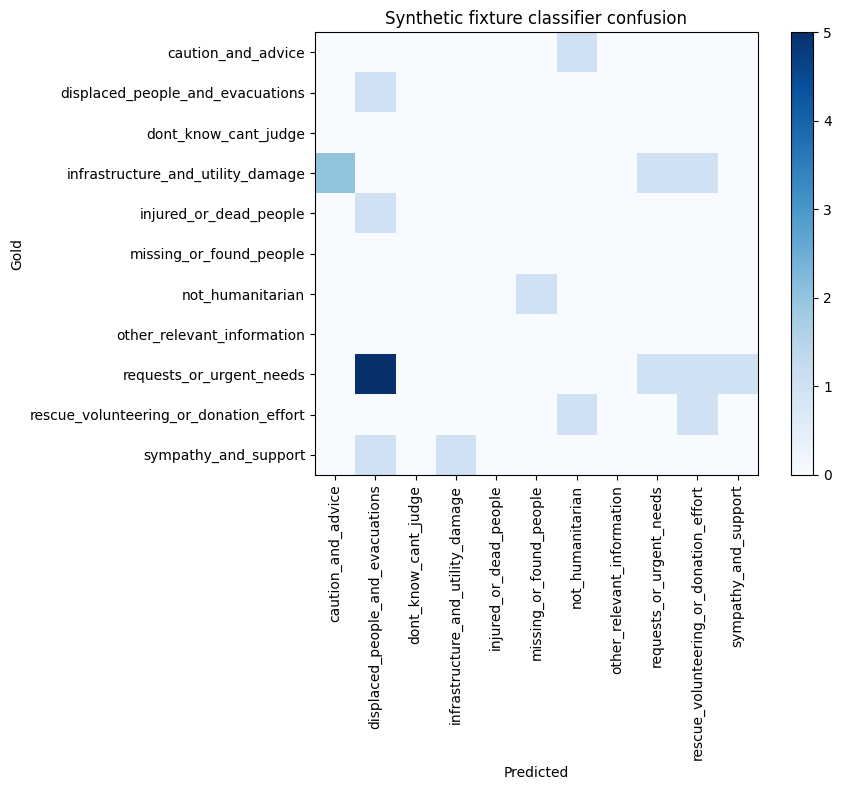

In [7]:
with patch.object(config, 'CLASSIFIER_PATH', classifier_path), patch.object(config, 'OUTPUTS', outputs_root):
    ev = tag.evaluate_classifier(event)
display(pd.DataFrame({'category': ev['labels'], 'F1': [ev['per_class_f1'][c] for c in ev['labels']]}))
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(ev['confusion'], cmap='Blues')
ax.set(xticks=range(len(ev['labels'])), yticks=range(len(ev['labels'])),
       xticklabels=ev['labels'], yticklabels=ev['labels'], xlabel='Predicted', ylabel='Gold',
       title='Synthetic fixture classifier confusion' if FIXTURE_MODE else 'Held-out event classifier confusion')
plt.setp(ax.get_xticklabels(), rotation=90)
fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()

In [8]:
reports = read_jsonl(config.event_file(event, config.REPORTS_FILE, stub=FIXTURE_MODE), Report)
tags = read_jsonl(config.event_file(event, config.TAGGED_FILE, stub=FIXTURE_MODE), Tagged)
display(pd.DataFrame([{'text': mask_privacy(r.text), 'pred_category': t.pred_category,
                       'places': t.places, 'county': t.county_fips, 'vuln_terms': t.vuln_terms}
                      for r, t in list(zip(reports, tags))[:10]]))

,text,pred_category,places,county,vuln_terms
0,Water rising fast on Braeswood in Meyerland Ho...,displaced_people_and_evacuations,[Houston],48201,"[grandma, trapped]"
1,"Rockport roofs torn off, power lines down acro...",rescue_volunteering_or_donation_effort,[Rockport],48007,[]
2,Elderly neighbor stuck in attic near Meyerland...,displaced_people_and_evacuations,[Houston],48201,[elderly]
3,"Beaumont has lost its water supply, hospitals ...",requests_or_urgent_needs,[Beaumont],48245,[]
4,Praying for everyone in Texas tonight,displaced_people_and_evacuations,[],None,[]
5,"Houston Meyerland area flooding badly, people ...",displaced_people_and_evacuations,[Houston],48201,[]
6,"Huge damage in Rockport, the high school roof ...",caution_and_advice,[Rockport],48007,[]
7,"Please help, water is coming into the house an...",sympathy_and_support,[],None,[newborn]
8,Two people injured when a tree fell on a car i...,displaced_people_and_evacuations,[Port Arthur],48245,[]
9,Anyone have a boat near Meyerland Houston? Fam...,displaced_people_and_evacuations,[Houston],48201,[stranded]


## Measurement provenance
The following line reports the architecture observed by the bootstrap. Fixture runs are development checks, not LinuxONE results.

In [9]:
display(Markdown(f"Numbers above were produced on: **{ENV['arch']}**. Mode: {'synthetic fixtures' if FIXTURE_MODE else 'real data'}"))
if fixture_model_dir is not None:
    fixture_model_dir.cleanup()

Numbers above were produced on: **arm64**. Mode: synthetic fixtures